T1: PPO CartPole

PPO completo para acciones discretas


In [1]:
import torch, torch.nn as nn, numpy as np, gymnasium as gym
from torch.distributions import Categorical
import matplotlib.pyplot as plt

# ── Red compartida (misma que A2C) ─────────────────────────
class PPONet(nn.Module):
    def __init__(self, s_dim, n_act, hidden=256):
        super().__init__()
        self.tronco = nn.Sequential(nn.Linear(s_dim,hidden),nn.Tanh(),
                                     nn.Linear(hidden,hidden),nn.Tanh())
        self.actor  = nn.Linear(hidden, n_act)
        self.critic = nn.Linear(hidden, 1)
    def forward(self, x):
        f = self.tronco(x)
        return Categorical(logits=self.actor(f)), self.critic(f).squeeze(-1)

env   = gym.make("CartPole-v1")
model = PPONet(4, 2)
opt   = torch.optim.Adam(model.parameters(), lr=3e-4)

# ── Recolectar T pasos ─────────────────────────────────────
def collect(env, model, T=512, gamma=0.99, lam=0.95):
    S,A,LP,V,R,D = [],[],[],[],[],[]
    obs,_ = env.reset()
    for _ in range(T):
        s = torch.FloatTensor(obs)
        dist,val= model(s)
        a = dist.sample()
        lp = dist.log_prob(a).detach()
        obs,r,te,tr,_ = env.step(a.item())
        S.append(s);A.append(a);LP.append(lp);V.append(val.detach());R.append(r);D.append(te or tr)
        if te or tr: obs,_ = env.reset()
    # GAE
    V_t = torch.stack(V)
    nv = model(torch.FloatTensor(obs))[1].detach()
    adv = torch.zeros(T)
    gae=0
    for t in reversed(range(T)):
        mask=1-float(D[t]); vnxt=V_t[t+1].item() if t<T-1 else nv.item()
        delta=R[t]+gamma*vnxt*mask-V_t[t].item()
        gae=delta+gamma*lam*mask*gae; adv[t]=gae
    ret = adv + V_t
    return torch.stack(S),torch.stack(A),torch.stack(LP),adv,ret


Función de update PPO y loop principal


In [ ]:
def ppo_update(model, opt, S, A, LP_old, adv, ret,
               K=10, eps=0.2, c_v=0.5, c_e=0.01, mb=256):
    adv_n = (adv-adv.mean())/(adv.std()+1e-8)
    T = len(S)
    ratio_log = []
    for _ in range(K):
        for s in range(0,T,mb):
            idx = torch.randperm(T)[s:s+mb]
            dist_n,val_n = model(S[idx])
            lp_n = dist_n.log_prob(A[idx])
            ratio = (lp_n - LP_old[idx]).exp()
            ratio_log.append(ratio.mean().item())  # monitorear!
            L1 = ratio * adv_n[idx]
            L2 = ratio.clamp(1-eps, 1+eps) * adv_n[idx]
            loss = -(torch.min(L1,L2).mean()) + c_v*(val_n-ret[idx]).pow(2).mean() - c_e*dist_n.entropy().mean()
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 0.5); opt.step()
    return np.mean(ratio_log)

# ── Loop PPO CartPole ─────────────────────────────────────
reward_hist, ratio_hist = [], []
for it in range(100):
    S,A,LP,adv,ret = collect(env, model, T=512)
    r_mean = ppo_update(model, opt, S, A, LP, adv, ret)
    ratio_hist.append(r_mean)
    ep_r = sum([1 for r in ret.tolist() if r > 0]) / 512 * 500  # proxy de reward
    reward_hist.append(ret.mean().item())
    if (it + 1) % 20 == 0 or it == 0:
        print(f"Iteración {it+1:3d}/100 | Retorno GAE medio: {ret.mean().item():6.2f} | Ratio medio: {r_mean:.4f}")

Evaluación y visualización de resultados en CartPole-v1


T2 - PPO PENDULUM


Red PPO para acciones continuas


In [10]:
from torch.distributions import Normal

class PPOContNet(nn.Module):
    """PPO con salida Gaussiana para acciones continuas."""
    def __init__(self, s_dim, a_dim, hidden=256):
        super().__init__()
        self.tronco = nn.Sequential(nn.Linear(s_dim,hidden),nn.Tanh(),
                                     nn.Linear(hidden,hidden),nn.Tanh())
        self.mu_head  = nn.Linear(hidden, a_dim)
        self.log_std  = nn.Parameter(torch.zeros(a_dim))   # std aprendible
        self.v_head   = nn.Linear(hidden, 1)

    def forward(self, x):
        f   = self.tronco(x)
        mu  = self.mu_head(f)
        std = self.log_std.exp().clamp(1e-3, 2.0)  # evitar std=0 o muy grande
        return Normal(mu, std), self.v_head(f).squeeze(-1)

env_p   = gym.make("Pendulum-v1")
s_dim_p = env_p.observation_space.shape[0]  # 3: [cos, sin, dθ/dt]
a_dim_p = env_p.action_space.shape[0]        # 1: torque ∈ [−2, 2]
model_p = PPOContNet(s_dim_p, a_dim_p)
opt_p   = torch.optim.Adam(model_p.parameters(), lr=3e-4)

# Verificar
s_test = torch.FloatTensor(env_p.reset()[0]).unsqueeze(0)
dist_t, val_t = model_p(s_test)
print(f"mu: {dist_t.loc.item():.3f}  std: {dist_t.scale.item():.3f}  V: {val_t.item():.3f}")


mu: 0.032  std: 1.000  V: -0.021


Adaptar collect() para acciones continuas


In [11]:
def collect_cont(env, model, T=2048, gamma=0.99, lam=0.95):
    """Igual que collect() pero para acciones continuas."""
    S,A,LP,V,R,D = [],[],[],[],[],[]
    obs,_ = env.reset()
    for _ in range(T):
        s = torch.FloatTensor(obs)
        dist, val = model(s)
        a    = dist.sample()
        lp   = dist.log_prob(a).sum(-1).detach()  # .sum(-1) para multi-dim
        a_np = a.detach().numpy().clip(
            env.action_space.low, env.action_space.high)  # clip al rango!
        obs,r,te,tr,_ = env.step(a_np)
        S.append(s);A.append(a)
        LP.append(lp)
        V.append(val.detach())
        R.append(r/8.0)# /8.0: normalizar reward de Pendulum
        D.append(te or tr)
        if te or tr: obs,_ = env.reset()
    # GAE
    V_t = torch.stack(V); nv = model(torch.FloatTensor(obs))[1].detach()
    adv = torch.zeros(T); gae=0
    for t in reversed(range(T)):
        mask=1-float(D[t]); vnxt=V_t[t+1].item() if t<T-1 else nv.item()
        delta=R[t]+gamma*vnxt*mask-V_t[t].item()
        gae=delta+gamma*lam*mask*gae; adv[t]=gae
    ret = adv + V_t


    return torch.stack(S), torch.stack(A), torch.stack(LP), adv, ret

# ── Entrena PPO en Pendulum ────────────────────────────────
rewards_pend = []
for it in range(300):
    S,A,LP,adv,ret = collect_cont(env_p, model_p, T=2048)
    ppo_update(model_p, opt_p, S, A, LP, adv, ret,
               K=10, eps=0.2, c_v=0.5, c_e=0.0)  # c_e=0 para Pendulum
    rewards_pend.append(ret.mean().item())
    if it % 30 == 0:
        print(f"Iter {it:>3d} | R_mean={ret.mean():.2f}")


Iter   0 | R_mean=-11.32
Iter  30 | R_mean=-58.46
Iter  60 | R_mean=-60.81
Iter  90 | R_mean=-61.46
Iter 120 | R_mean=-63.71
Iter 150 | R_mean=-61.97
Iter 180 | R_mean=-63.96
Iter 210 | R_mean=-60.78
Iter 240 | R_mean=-59.43
Iter 270 | R_mean=-62.98


In [5]:
def ppo_update_monitored(model, opt, S, A, LP_old, adv, ret,
                          K=10, eps=0.2, c_v=0.5, c_e=0.0, mb=256):
    """PPO update con monitoreo del ratio."""
    adv_n = (adv-adv.mean())/(adv.std()+1e-8); T=len(S)
    epoch_ratios, epoch_clipped_frac = [], []

    for epoch in range(K):
        ratios_ep = []
        for s in range(0,T,mb):
            idx = torch.randperm(T)[s:s+mb]
            dist_n, val_n = model(S[idx])
            lp_n = dist_n.log_prob(A[idx]).sum(-1)
            ratio = (lp_n - LP_old[idx]).exp()
            ratios_ep.extend(ratio.detach().tolist())
            # ... loss y update ...
        epoch_ratios.append(np.mean(ratios_ep))
        clipped = np.mean([r < 1-eps or r > 1+eps for r in ratios_ep])
        epoch_clipped_frac.append(clipped)
    return epoch_ratios, epoch_clipped_frac

# Visualizar para 1 iteracion
ratios_by_epoch, clipped_by_epoch = ppo_update_monitored(
    model_p, opt_p, S, A, LP, adv, ret)

fig, (ax1,ax2) = plt.subplots(1,2,figsize=(12,4))
ax1.plot(ratios_by_epoch, 'o-', color='#00AEEF', lw=2)
ax1.axhline(1.0, color='gray', ls='--', lw=1)
ax1.axhline(1+0.2, color='red', ls=':', lw=1, label='1+ε')
ax1.axhline(1-0.2, color='red', ls=':', lw=1, label='1-ε')
ax1.set_title('Ratio medio por epoch'); ax1.legend(); ax1.grid(alpha=0.3)
ax2.bar(range(len(clipped_by_epoch)), clipped_by_epoch, color='#EA580C')
ax2.set_title('Fraccion de ratios fuera del clip [0,1]'); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()


NameError: name 'S' is not defined

K=1, ε=0.1: -41.287
K=1, ε=0.2: -40.885
K=1, ε=0.3: -39.066
K=5, ε=0.1: -59.273
K=5, ε=0.2: -58.004
K=5, ε=0.3: -59.844
K=10, ε=0.1: -59.168
K=10, ε=0.2: -59.642
K=10, ε=0.3: -60.116


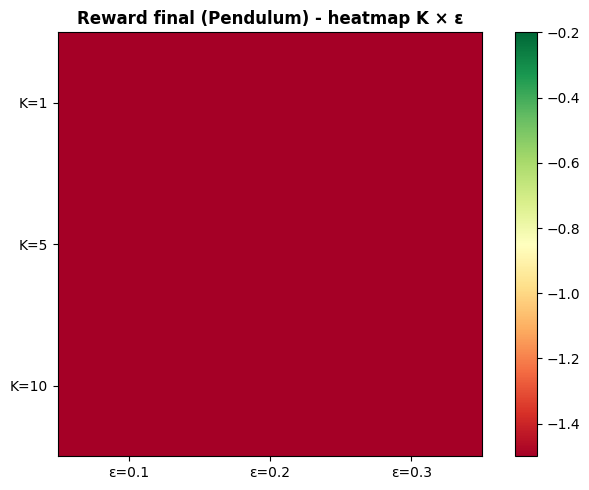

In [ ]:
# Barrido: K ∈ {1, 5, 10}  y  ε ∈ {0.1, 0.2, 0.3}
K_vals   = [1, 5, 10]
eps_vals = [0.1, 0.2, 0.3]
results  = {}

for K in K_vals:
    for eps in eps_vals:
        m  = PPOContNet(3, 1)
        o  = torch.optim.Adam(m.parameters(), lr=3e-4)
        rs = []
        for _ in range(100):               # 100 iteraciones (rapido)
            S,A,LP,adv,ret = collect_cont(env_p, m, T=1024)
            ppo_update(m, o, S, A, LP, adv, ret, K=K, eps=eps, c_e=0.0)
            rs.append(ret.mean().item())
        results[(K,eps)] = np.mean(rs[-20:])  # reward final
        print(f"K={K}, ε={eps}: {results[(K,eps)]:.3f}")

# Heatmap de resultados

mat = [[results[(K,eps)] for eps in eps_vals] for K in K_vals]
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(mat, cmap='RdYlGn', vmin=-1.5, vmax=-0.2)
ax.set_xticks(range(3)); ax.set_xticklabels([f'ε={e}' for e in eps_vals])
ax.set_yticks(range(3)); ax.set_yticklabels([f'K={k}' for k in K_vals])
ax.set_title('Reward final (Pendulum) - heatmap K × ε', fontweight='bold')
plt.colorbar(im); plt.tight_layout(); plt.show()
